# Кластеризация синтетических данных методом k-means

## Задание

Нужно выполнить кластерный анализ **k-means** для набора синтетических данных при заданном числе кластеров, построить раскрашенные диаграммы кластеров и силуэтные диаграммы, оценить качество с помощью `sklearn` и ответить, справился ли алгоритм с каждым набором и какие ограничения k-means этому помешали.

В таблице варианта перечислены 9 наборов. В приложении также есть файл `Aggregation.txt`, поэтому он добавлен в анализ: для него взято **k = 7** — по числу классов в файле. Таким образом, ниже разобраны все 10 приложенных наборов.

| № | Набор | Файл | Точек | k | Истинные метки |
|---:|---|---|---:|---:|---|
| 1 | A1 | `a1.txt` | 3000 | 20 | нет |
| 2 | Aggregation | `Aggregation.txt` | 788 | 7 | да |
| 3 | Compound | `Compound.txt` | 399 | 6 | да |
| 4 | D31 | `D31.txt` | 3100 | 31 | да |
| 5 | Flame | `flame.txt` | 240 | 2 | да |
| 6 | Jain | `jain.txt` | 373 | 2 | да |
| 7 | Pathbased | `pathbased.txt` | 300 | 3 | да |
| 8 | R15 | `R15.txt` | 600 | 15 | да |
| 9 | S1 | `s1.txt` | 5000 | 15 | нет |
| 10 | Spiral | `spiral.txt` | 312 | 3 | да |

Все данные лежат в папке `data/`; ноутбук использует только относительные пути, поэтому его можно запускать из корня проекта.

**Что требуется по пунктам:**

1. выполнить кластеризацию k-means на Python для каждого набора при заданном k;
2. построить раскрашенные диаграммы кластеров;
3. построить силуэтные диаграммы и оценить качество кластеризации средствами `sklearn`;
4. ответить, справился ли алгоритм, и объяснить, какие ограничения k-means помешали.

## 1. Импорт библиотек и настройки

Фиксируем `random_state` и число запусков `n_init`, чтобы результат воспроизводился. Для всех наборов используется одна и та же реализация `KMeans` из `scikit-learn`.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import sklearn
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    normalized_mutual_info_score,
    silhouette_samples,
    silhouette_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_INIT = 50
DATA_DIR = Path("data")

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#cccccc",
        "axes.grid": True,
        "grid.color": "#dddddd",
        "grid.linewidth": 0.6,
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    }
)

print(
    f"numpy {np.__version__} | pandas {pd.__version__} | "
    f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}"
)

numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 2. Загрузка данных

Файлы — текстовые таблицы с колонками `x1`, `x2` и, если разметка есть, `class`. Разделитель — пробелы или табуляция. Истинные метки **не передаются** в `KMeans`: они используются только после обучения для проверки (ARI, NMI) и для соседнего графика с истинными классами.

In [2]:
DATASETS = {
    "A1": {"file": "a1.txt", "k": 20},
    "Aggregation": {"file": "Aggregation.txt", "k": 7},
    "Compound": {"file": "Compound.txt", "k": 6},
    "D31": {"file": "D31.txt", "k": 31},
    "Flame": {"file": "flame.txt", "k": 2},
    "Jain": {"file": "jain.txt", "k": 2},
    "Pathbased": {"file": "pathbased.txt", "k": 3},
    "R15": {"file": "R15.txt", "k": 15},
    "S1": {"file": "s1.txt", "k": 15},
    "Spiral": {"file": "spiral.txt", "k": 3},
}


def load_dataset(path: Path):
    """Читает файл с координатами x1, x2 и необязательным столбцом class."""
    df = pd.read_csv(path, sep=r"\s+", header=0, engine="python")
    df.columns = [str(column).strip() for column in df.columns]

    if not {"x1", "x2"}.issubset(df.columns):
        raise ValueError(f"В файле {path.name} нет колонок x1 и x2: {list(df.columns)}")

    X = df[["x1", "x2"]].to_numpy(dtype=float)
    y = df["class"].to_numpy() if "class" in df.columns else None
    return X, y


DATA = {}
overview_rows = []

for name, spec in DATASETS.items():
    X, y = load_dataset(DATA_DIR / spec["file"])
    DATA[name] = (X, y)
    overview_rows.append(
        {
            "Набор": name,
            "Файл": spec["file"],
            "Точек": len(X),
            "Признаков": X.shape[1],
            "k": spec["k"],
            "Истинные метки": "да" if y is not None else "нет",
            "Классов в файле": len(np.unique(y)) if y is not None else "—",
        }
    )

overview = pd.DataFrame(overview_rows)
display(overview)

,Набор,Файл,Точек,Признаков,k,Истинные метки,Классов в файле
0,A1,a1.txt,3000,2,20,нет,—
1,Aggregation,Aggregation.txt,788,2,7,да,7
2,Compound,Compound.txt,399,2,6,да,6
3,D31,D31.txt,3100,2,31,да,31
4,Flame,flame.txt,240,2,2,да,2
5,Jain,jain.txt,373,2,2,да,2
6,Pathbased,pathbased.txt,300,2,3,да,3
7,R15,R15.txt,600,2,15,да,15
8,S1,s1.txt,5000,2,15,нет,—
9,Spiral,spiral.txt,312,2,3,да,3


## 3. Методика

**Модель.** K-means ищет k центроидов и минимизирует сумму квадратов расстояний точек до своих центроидов (инерцию). Каждая точка относится к ближайшему центроиду, поэтому границы кластеров — прямые линии, а сами кластеры выпуклые (ячейки Вороного).

**Параметры.** Для всех наборов: `n_init=50`, `random_state=42`. Большое `n_init` уменьшает риск попасть в неудачный локальный минимум. Признаки `x1` и `x2` — координаты в одних единицах, поэтому масштабирование не применяется: так геометрия данных на графике соответствует исходной.

**Внутренние метрики (без истинных меток):**

- **силуэт** — от −1 до 1; чем ближе к 1, тем компактнее кластер и дальше соседние;
- **Calinski–Harabasz (CH)** — отношение межкластерного разброса к внутрикластерному, больше — лучше;
- **Davies–Bouldin (DB)** — среднее «перекрытие» кластеров, меньше — лучше.

**Внешние метрики (только при наличии `class`):**

- **ARI** (Adjusted Rand Index) — согласие разбиения с истинными классами с поправкой на случайность; 1 — идеально, 0 — случайно;
- **NMI** (Normalized Mutual Information) — взаимная информация между разбиением и классами; 1 — идеально.

Силуэтная диаграмма строится по всем точкам: для каждого кластера значения $s(i)$ сортируются и рисуются горизонтальной полосой; красная пунктирная линия — средний силуэт.

## 4. Вспомогательные функции

Ниже — единые функции загрузки результатов, графиков и метрик, чтобы все 10 наборов обрабатывались одинаково.

In [3]:
RESULTS = {}


def make_palette(n: int):
    """Достаточно различимая палитра для 2–31 кластера."""
    if n <= 10:
        cmap = plt.get_cmap("tab10")
        return [cmap(i) for i in range(n)]
    if n <= 20:
        cmap = plt.get_cmap("tab20")
        return [cmap(i) for i in range(n)]

    # Для 21–31 кластера объединяем три качественные палитры,
    # чтобы избежать почти чёрных и серых цветов nipy_spectral.
    colors = []
    for cmap_name in ("tab20", "tab20b", "tab20c"):
        cmap = plt.get_cmap(cmap_name)
        colors.extend(cmap(i) for i in range(20))
    return colors[:n]


def fmt(value, digits: int = 3, dash: str = "—") -> str:
    if value is None:
        return dash
    if isinstance(value, float) and np.isnan(value):
        return dash
    return f"{value:.{digits}f}"


def scatter_clusters(ax, X, labels, title, palette, centers=None):
    labels = np.asarray(labels)
    if len(X) > 2000:
        point_size = 7
    elif len(X) > 500:
        point_size = 12
    else:
        point_size = 17

    for color_idx, label in enumerate(np.unique(labels)):
        mask = labels == label
        ax.scatter(
            X[mask, 0],
            X[mask, 1],
            s=point_size,
            color=palette[color_idx % len(palette)],
            alpha=0.82,
            linewidths=0,
            edgecolors="none",
        )

    if centers is not None:
        ax.scatter(
            centers[:, 0],
            centers[:, 1],
            marker="X",
            s=110,
            c="#111111",
            edgecolors="white",
            linewidths=1.1,
            zorder=10,
            label="центроиды",
        )
        ax.legend(loc="best", fontsize=8, frameon=True)

    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(True, alpha=0.25)


def plot_cluster_figure(result):
    X = result["X"]
    y = result["y"]
    labels = result["labels"]
    k = result["k"]
    ncols = 2 if y is not None else 1

    fig, axes = plt.subplots(1, ncols, figsize=(6.6 * ncols, 5.4), squeeze=False)
    axes = axes.ravel()

    scatter_clusters(
        axes[0],
        X,
        labels,
        f"{result['name']}: кластеры k-means, k = {k}",
        result["palette"],
        centers=result["model"].cluster_centers_,
    )

    if y is not None:
        true_palette = make_palette(len(np.unique(y)))
        scatter_clusters(
            axes[1],
            X,
            y,
            f"{result['name']}: истинные классы",
            true_palette,
        )

    fig.suptitle(
        f"{result['name']} — {len(X)} точек",
        fontsize=14,
        fontweight="bold",
    )
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()


def plot_silhouette(result):
    labels = result["labels"]
    samples = result["sil_samples"]
    k = result["k"]
    height = float(np.clip(3.0 + 0.32 * k, 5.0, 12.5))

    fig, ax = plt.subplots(figsize=(7.6, height))
    y_lower = 10
    label_size = 7 if k > 20 else 8

    for cluster in range(k):
        values = samples[labels == cluster]
        if values.size == 0:
            continue
        values = np.sort(values)
        upper = y_lower + values.size
        ax.fill_betweenx(
            np.arange(y_lower, upper),
            0,
            values,
            facecolor=result["palette"][cluster],
            edgecolor=result["palette"][cluster],
            linewidth=0,
            alpha=0.85,
        )
        ax.text(
            -0.012,
            y_lower + 0.5 * values.size,
            str(cluster),
            ha="right",
            va="center",
            fontsize=label_size,
        )
        y_lower = upper + 10

    ax.axvline(
        result["silhouette"],
        color="#c0392b",
        linestyle="--",
        linewidth=1.5,
        label=f"среднее = {result['silhouette']:.3f}",
    )
    xmin = min(-0.1, float(samples.min()) - 0.05)
    ax.set_xlim(xmin, 1.0)
    ax.set_ylim(0, y_lower)
    ax.set_yticks([])
    ax.set_xlabel("Коэффициент силуэта $s(i)$")
    ax.set_ylabel("Кластеры (точки отсортированы по $s(i)$)")
    ax.set_title(f"{result['name']}: силуэтная диаграмма, k = {k}")
    ax.legend(loc="lower right", frameon=True)
    ax.grid(True, axis="x", alpha=0.25)
    fig.tight_layout()
    plt.show()


def analyze_dataset(name: str):
    spec = DATASETS[name]
    X, y = DATA[name]
    k = spec["k"]

    model = KMeans(
        n_clusters=k,
        n_init=N_INIT,
        random_state=RANDOM_STATE,
    )

    t0 = time.perf_counter()
    labels = model.fit_predict(X)
    elapsed = time.perf_counter() - t0

    sil_values = silhouette_samples(X, labels)
    sil = float(silhouette_score(X, labels))
    ch = float(calinski_harabasz_score(X, labels))
    db = float(davies_bouldin_score(X, labels))

    ari = float(adjusted_rand_score(y, labels)) if y is not None else np.nan
    nmi = float(normalized_mutual_info_score(y, labels)) if y is not None else np.nan

    result = {
        "name": name,
        "X": X,
        "y": y,
        "k": k,
        "model": model,
        "labels": labels,
        "silhouette": sil,
        "sil_samples": sil_values,
        "ari": ari,
        "nmi": nmi,
        "ch": ch,
        "db": db,
        "n_iter": int(model.n_iter_),
        "inertia": float(model.inertia_),
        "time": elapsed,
        "sizes": np.bincount(labels, minlength=k),
        "palette": make_palette(k),
    }
    RESULTS[name] = result
    return result


def run_case(name: str):
    result = analyze_dataset(name)
    sizes = result["sizes"]
    ratio = sizes.max() / sizes.min()

    display(
        Markdown(
            f"**Метрики:** силуэт = **{result['silhouette']:.3f}**, "
            f"ARI = **{fmt(result['ari'])}**, NMI = **{fmt(result['nmi'])}**, "
            f"CH = **{result['ch']:.1f}**, DB = **{result['db']:.3f}**, "
            f"итераций = **{result['n_iter']}**; "
            f"размеры кластеров: **{sizes.min()}–{sizes.max()}** "
            f"(отношение max/min ≈ **{ratio:.1f}×**)."
        )
    )

    plot_cluster_figure(result)
    plot_silhouette(result)
    return result

## 5. Результаты по наборам

### 5.1. A1 — 20 кластеров

`data/a1.txt` · **3000 точек** · истинных меток в файле нет.

A1 состоит из 20 достаточно компактных групп. Это благоприятный сценарий для k-means, но из-за отсутствия `class` качество можно оценивать только по внутренним метрикам и визуально.

**Метрики:** силуэт = **0.595**, ARI = **—**, NMI = **—**, CH = **13830.0**, DB = **0.527**, итераций = **5**; размеры кластеров: **143–158** (отношение max/min ≈ **1.1×**).

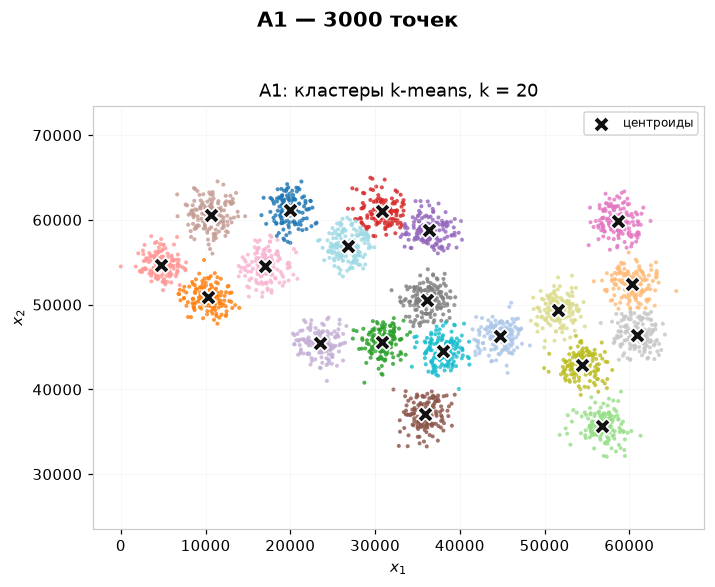

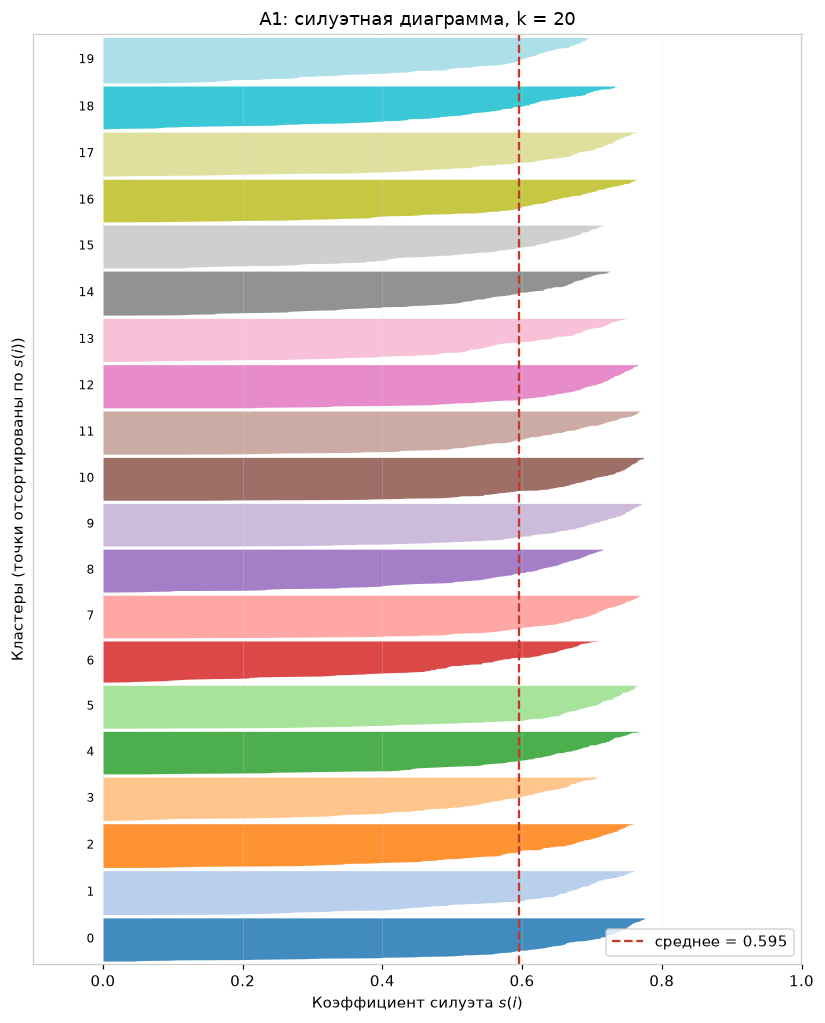

In [4]:
res_a1 = run_case('A1')

**Вывод.** K-means выделил 20 компактных групп; силуэт около 0,60, кластеры близки по размеру (143–158 точек). По внутренним метрикам и визуально разбиение выглядит убедительно. Без истинных меток нельзя доказать совпадение с «заводской» разметкой, но структура данных явно блобовая, и алгоритм с ней справляется.

### 5.2. Aggregation — 7 кластеров

`data/Aggregation.txt` · **788 точек** · 7 классов · размеры классов 34–273.

Классы заметно различаются по размеру, а некоторые группы соприкасаются. Для k-means это сложнее, чем однородные блобы: он может разрезать большую группу или слить маленькие соседние.

**Метрики:** силуэт = **0.481**, ARI = **0.762**, NMI = **0.879**, CH = **1396.6**, DB = **0.731**, итераций = **5**; размеры кластеров: **47–168** (отношение max/min ≈ **3.6×**).

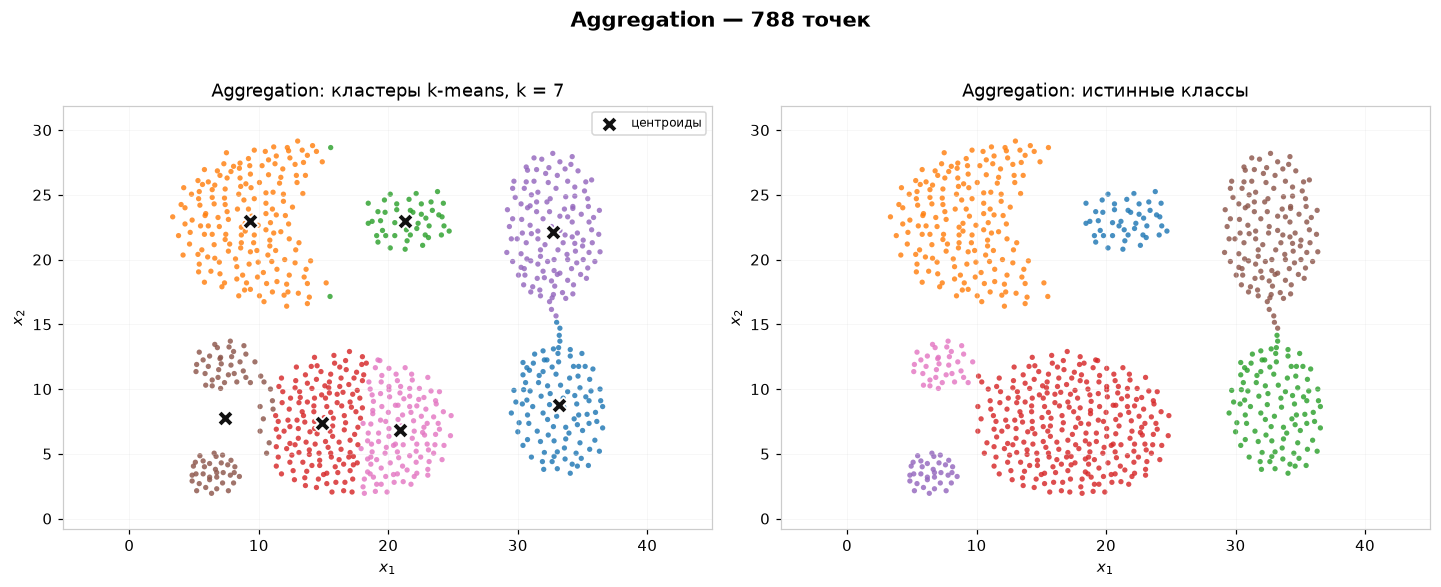

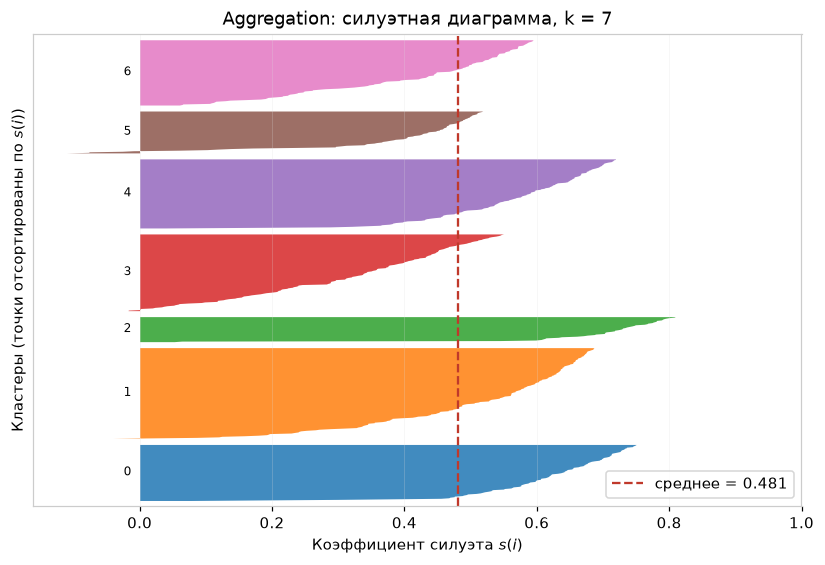

In [5]:
res_aggregation = run_case('Aggregation')

**Вывод.** ARI ≈ 0,76 — структура в основном восстановлена, но не идеально. Большой класс 4 разрезан на два кластера, а две маленькие соседние группы (классы 5 и 7) слиты в один. Причина в том, что k-means оптимизирует компактность и строит выпуклые границы, а не учитывает плотность и форму групп.

### 5.3. Compound — 6 кластеров

`data/Compound.txt` · **399 точек** · 6 классов · размеры классов 16–158.

Один большой класс имеет внутреннюю структуру, есть близкие и мелкие группы. При фиксированном `k = 6` k-means вынужден разбить данные на шесть компактных частей, даже если естественная структура не совпадает с числом классов.

**Метрики:** силуэт = **0.432**, ARI = **0.538**, NMI = **0.719**, CH = **870.6**, DB = **0.845**, итераций = **10**; размеры кластеров: **39–90** (отношение max/min ≈ **2.3×**).

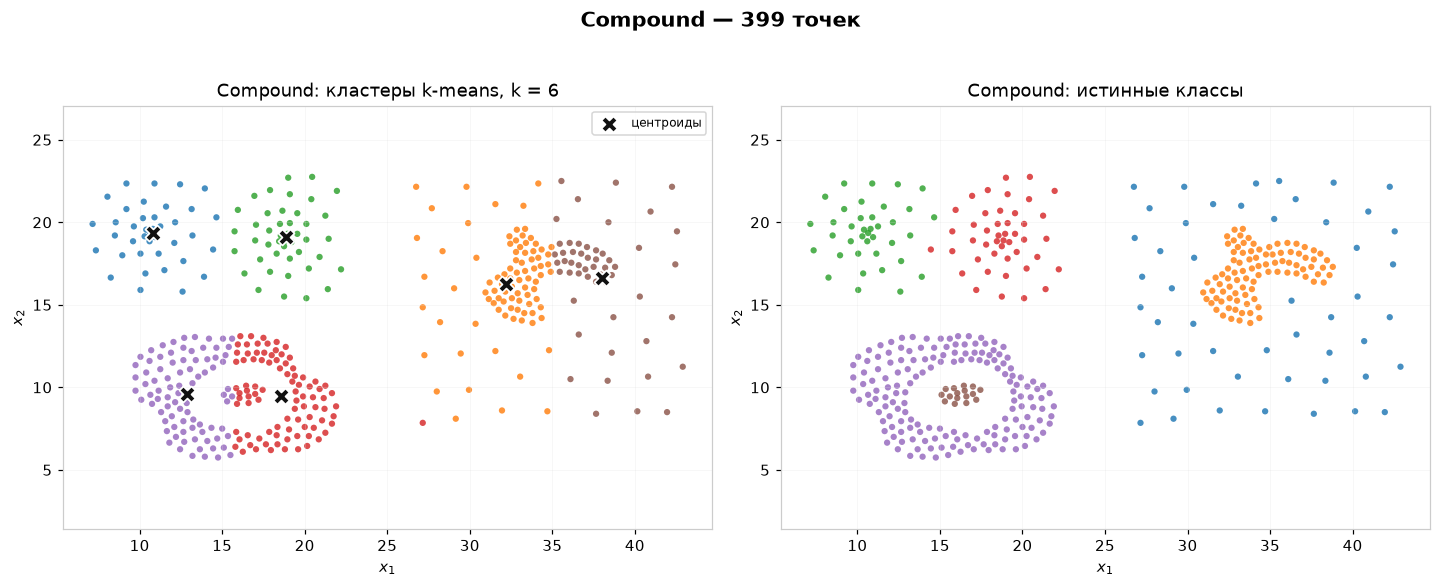

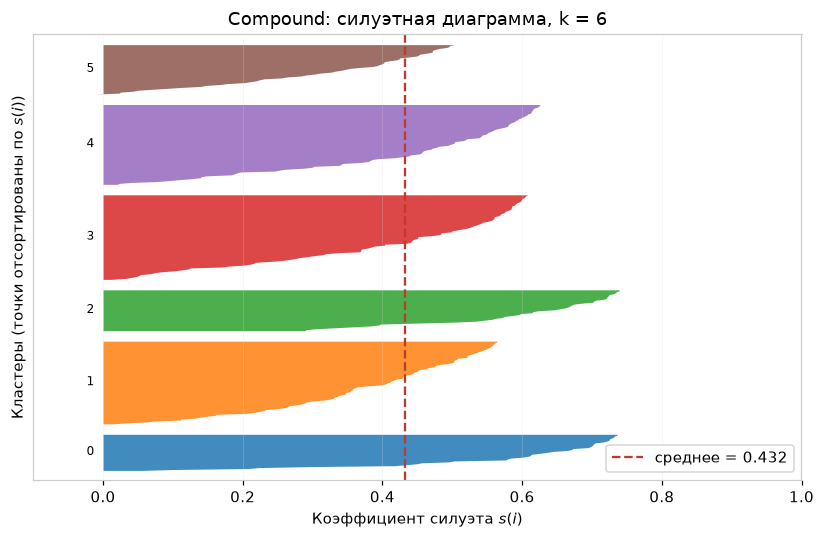

In [6]:
res_compound = run_case('Compound')

**Вывод.** ARI ≈ 0,54. Большой класс 5 разделён на два кластера, класс 6 «размазан» между ними, а части классов 1 и 2 попали в разные кластеры. Это типичная ошибка k-means при неравных размерах и сложной форме: большие облака режутся, а близкие мелкие группы объединяются. С восстановлением истинных классов алгоритм не справился.

### 5.4. D31 — 31 кластер

`data/D31.txt` · **3100 точек** · 31 класс по 100 точек.

D31 — почти идеальный для k-means набор: много хорошо разделённых компактных групп одинакового размера.

**Метрики:** силуэт = **0.576**, ARI = **0.954**, NMI = **0.968**, CH = **9168.1**, DB = **0.547**, итераций = **15**; размеры кластеров: **96–104** (отношение max/min ≈ **1.1×**).

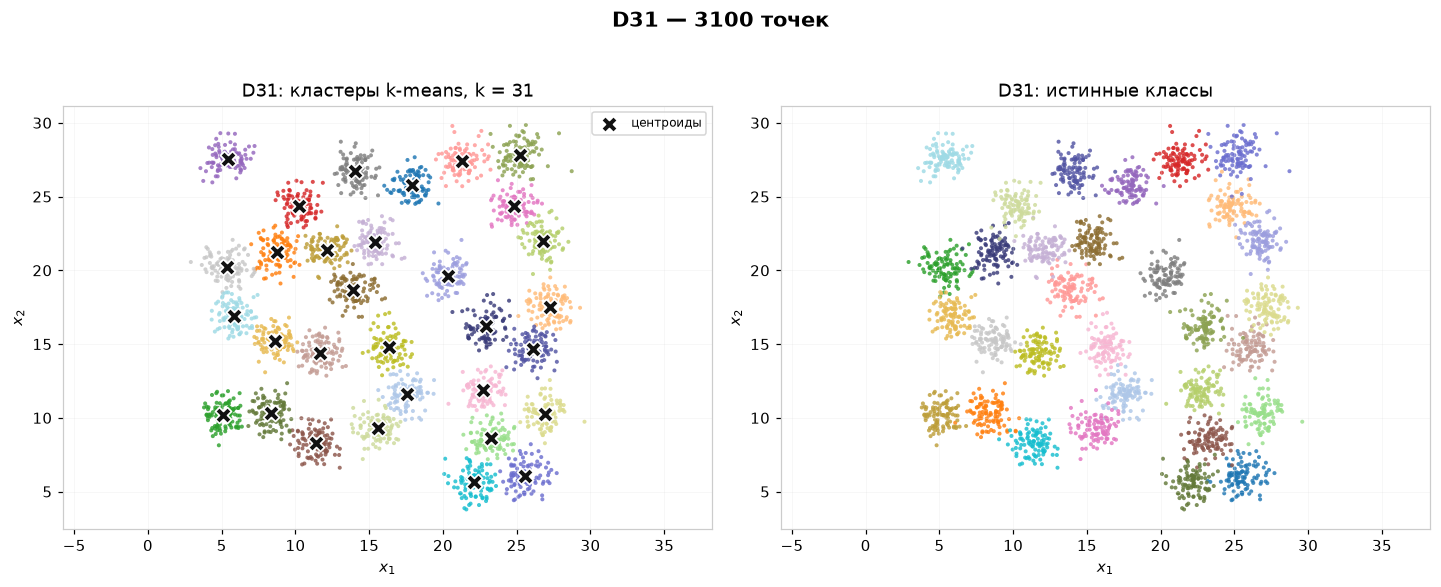

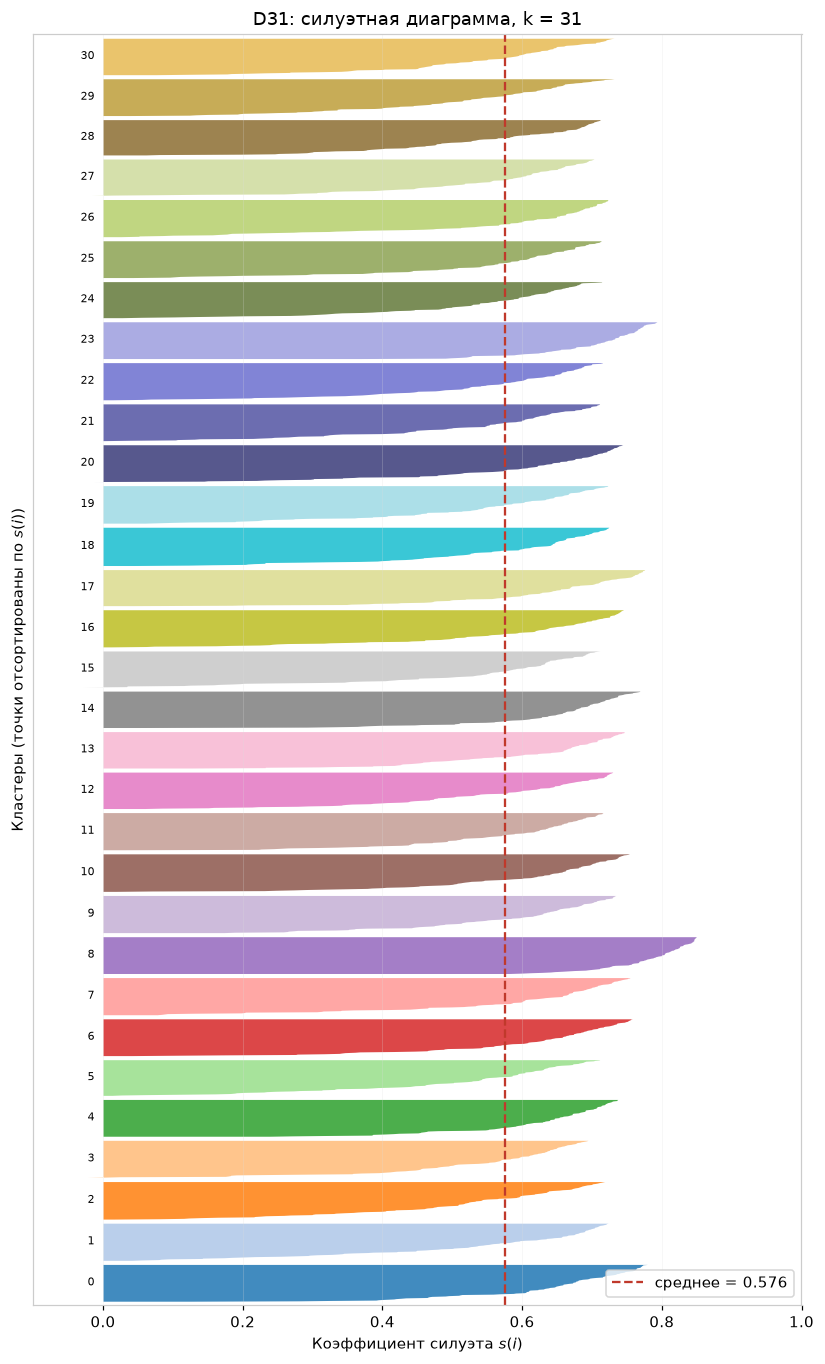

In [7]:
res_d31 = run_case('D31')

**Вывод.** ARI ≈ 0,95, NMI ≈ 0,97, силуэт ≈ 0,58. Почти все точки отнесены к своим классам, ошибки единичны и находятся на границах. K-means уверенно справился с задачей.

### 5.5. Flame — 2 кластера

`data/flame.txt` · **240 точек** · 2 класса (87 и 153 точки).

Кластеры вытянутые, граница между ними не является прямой, а плотность и размер групп различаются. Это уже не «два круглых облака».

**Метрики:** силуэт = **0.378**, ARI = **0.453**, NMI = **0.399**, CH = **157.2**, DB = **1.115**, итераций = **4**; размеры кластеров: **114–126** (отношение max/min ≈ **1.1×**).

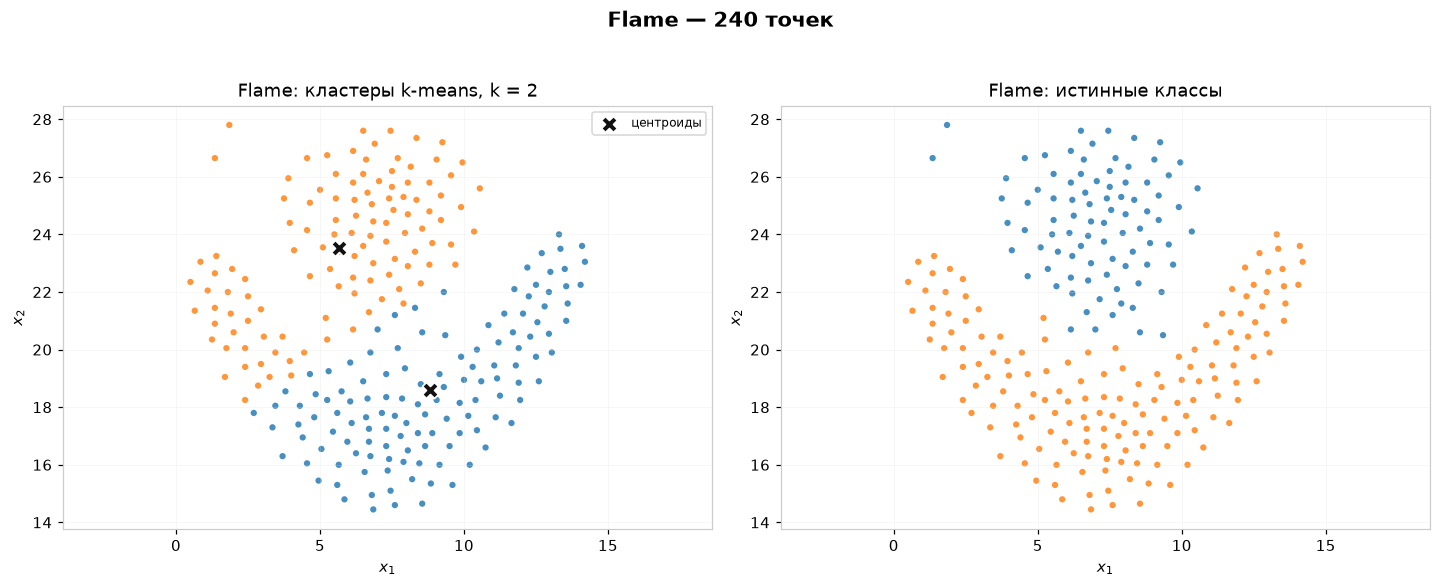

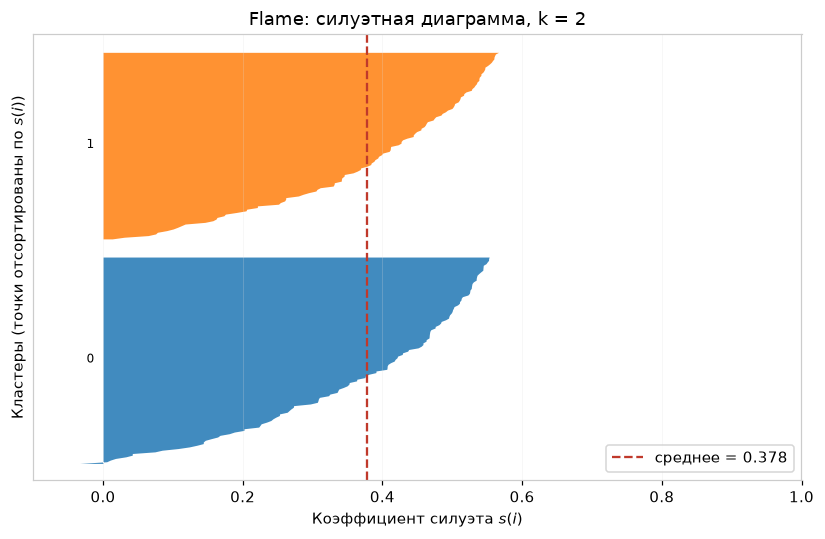

In [8]:
res_flame = run_case('Flame')

**Вывод.** ARI ≈ 0,45, силуэт ≈ 0,38. Один кластер почти соответствует классу 1, но линейная граница срезает часть класса 2 и относит её к другому кластеру. Форма облака не описывается двумя компактными кругами, поэтому k-means справляется лишь частично.

### 5.6. Jain — 2 кластера

`data/jain.txt` · **373 точки** · 2 класса (276 и 97 точек).

Классы имеют серповидную/изогнутую форму, разный размер и разную плотность. Такая структура не является выпуклой, поэтому k-means должен испытывать трудности.

**Метрики:** силуэт = **0.495**, ARI = **0.318**, NMI = **0.366**, CH = **503.5**, DB = **0.783**, итераций = **3**; размеры кластеров: **176–197** (отношение max/min ≈ **1.1×**).

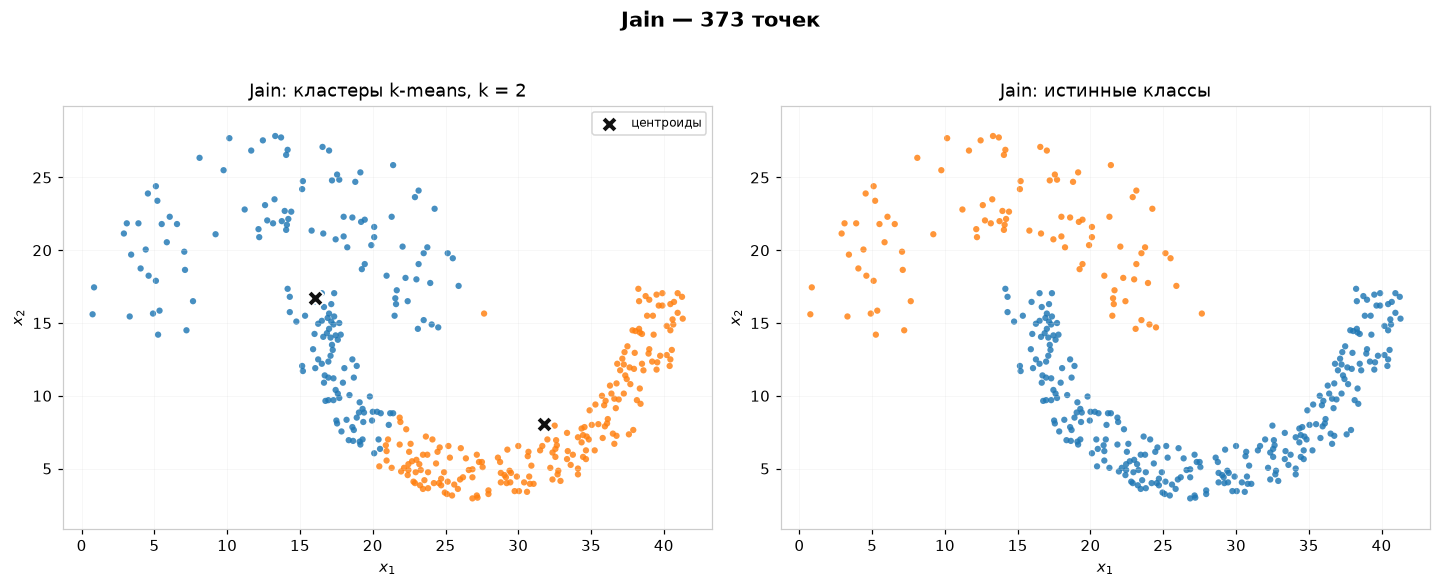

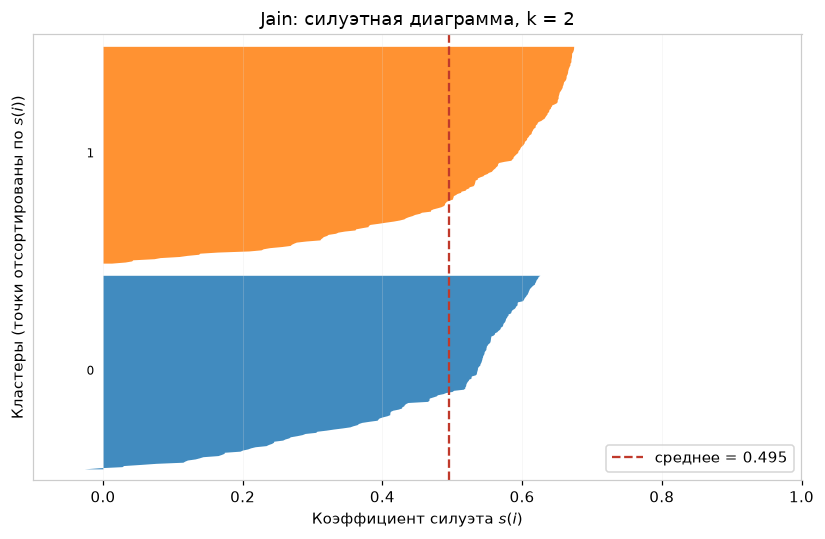

In [9]:
res_jain = run_case('Jain')

**Вывод.** ARI ≈ 0,32 при силуэте ≈ 0,50. K-means делит данные на два плотных «куска»: маленький класс 2 попадает в один кластер вместе с частью большого класса 1, а оставшаяся часть класса 1 образует второй кластер. Внутренняя метрика выглядит средней, но истинная структура не восстановлена: силуэт измеряет компактность и отделённость, а не соответствие изогнутой форме серпа.

### 5.7. Pathbased — 3 кластера

`data/pathbased.txt` · **300 точек** · 3 класса (110, 97 и 93 точки).

Здесь есть кольцевая (изогнутая) структура: внешнее кольцо класса 1 и две внутренние группы. K-means не умеет выделять кольца, потому что его кластеры всегда выпуклые.

**Метрики:** силуэт = **0.542**, ARI = **0.461**, NMI = **0.546**, CH = **359.1**, DB = **0.669**, итераций = **3**; размеры кластеров: **33–134** (отношение max/min ≈ **4.1×**).

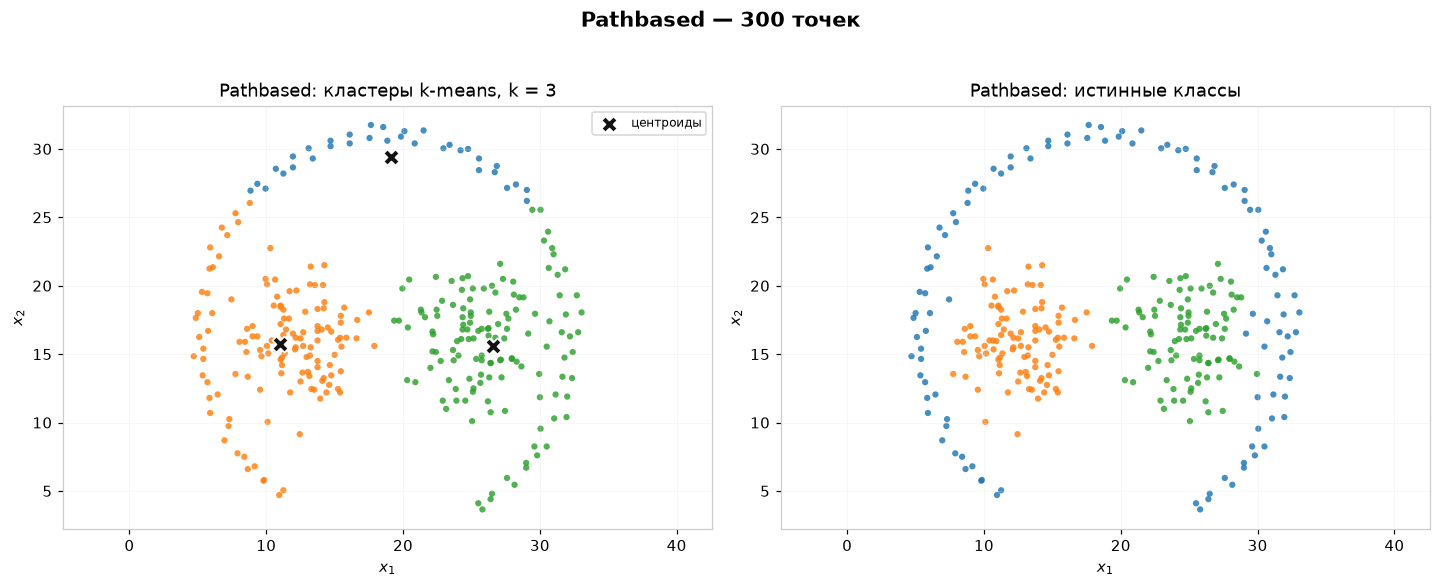

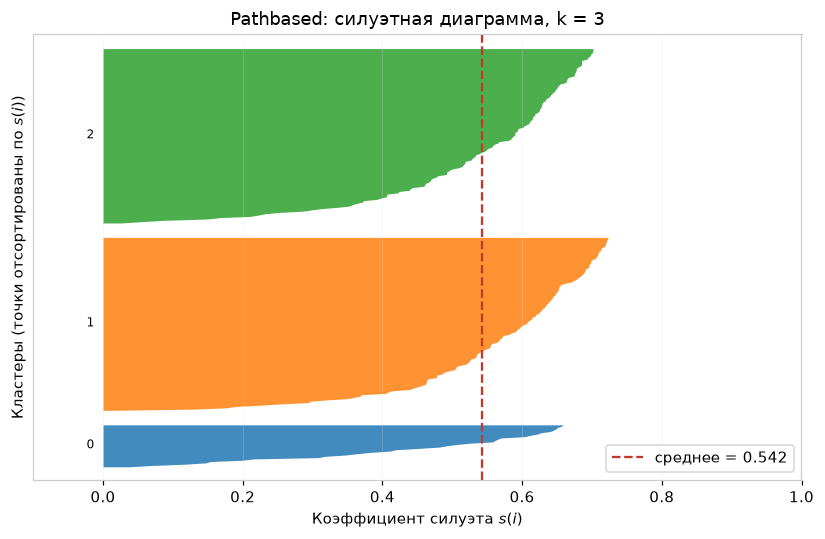

In [10]:
res_pathbased = run_case('Pathbased')

**Вывод.** ARI ≈ 0,46, силуэт ≈ 0,54. Два внутренних класса 2 и 3 восстановлены, но кольцо класса 1 разрезано на три части: одна стала отдельным кластером, две другие присоединились к внутренним группам. Это наглядный пример ограничения выпуклых границ: k-means «режет» кольцо, а не выделяет его целиком.

### 5.8. R15 — 15 кластеров

`data/R15.txt` · **600 точек** · 15 классов по 40 точек.

R15, как и D31, состоит из компактных хорошо разделённых групп одинакового размера — благоприятный сценарий для k-means.

**Метрики:** силуэт = **0.753**, ARI = **0.993**, NMI = **0.994**, CH = **4872.0**, DB = **0.315**, итераций = **7**; размеры кластеров: **39–41** (отношение max/min ≈ **1.1×**).

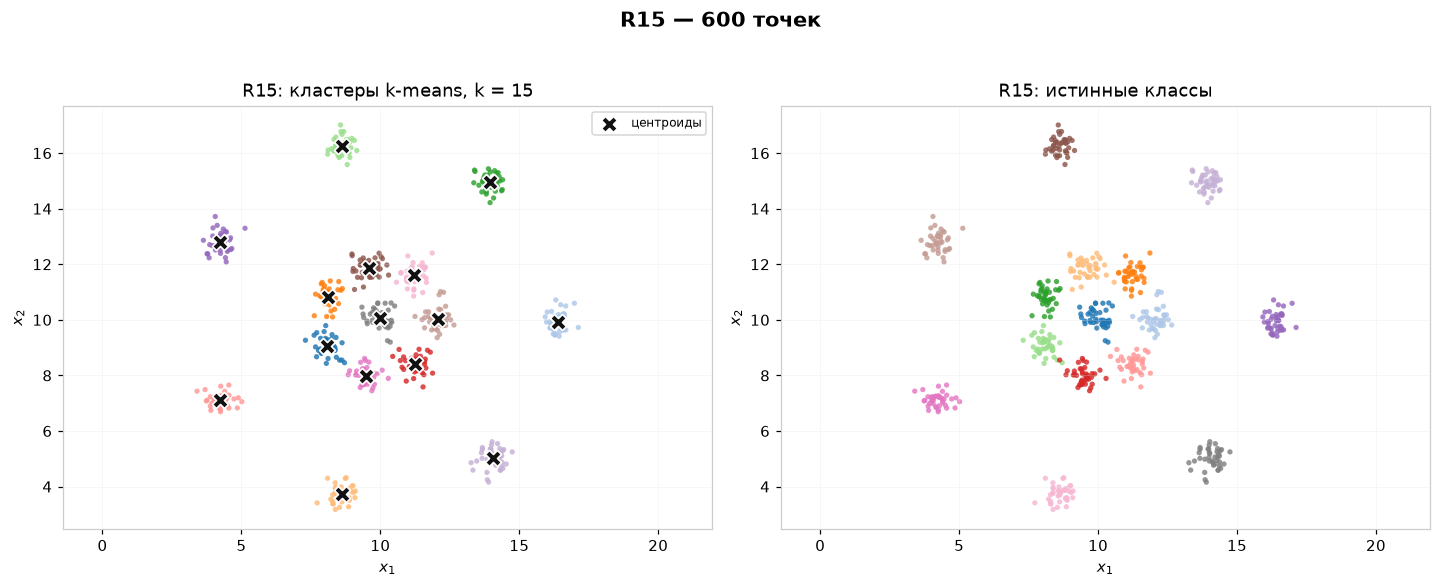

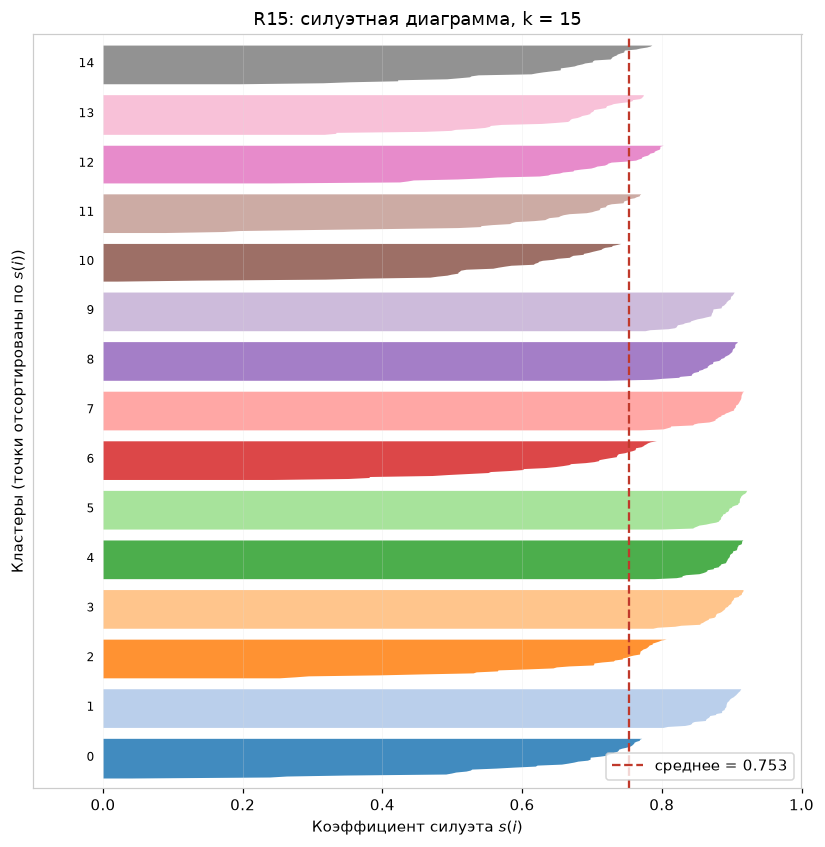

In [11]:
res_r15 = run_case('R15')

**Вывод.** ARI ≈ 0,99, силуэт ≈ 0,75. Разбиение практически совпадает с истинными классами, единичные ошибки — на границах. K-means отлично справился.

### 5.9. S1 — 15 кластеров

`data/s1.txt` · **5000 точек** · истинных меток в файле нет.

S1 — крупный набор из 15 компактных групп. Меток нет, поэтому ARI и NMI не вычисляются; ориентируемся на силуэт, CH/DB и визуальную картину.

**Метрики:** силуэт = **0.711**, ARI = **—**, NMI = **—**, CH = **22675.3**, DB = **0.367**, итераций = **5**; размеры кластеров: **297–352** (отношение max/min ≈ **1.2×**).

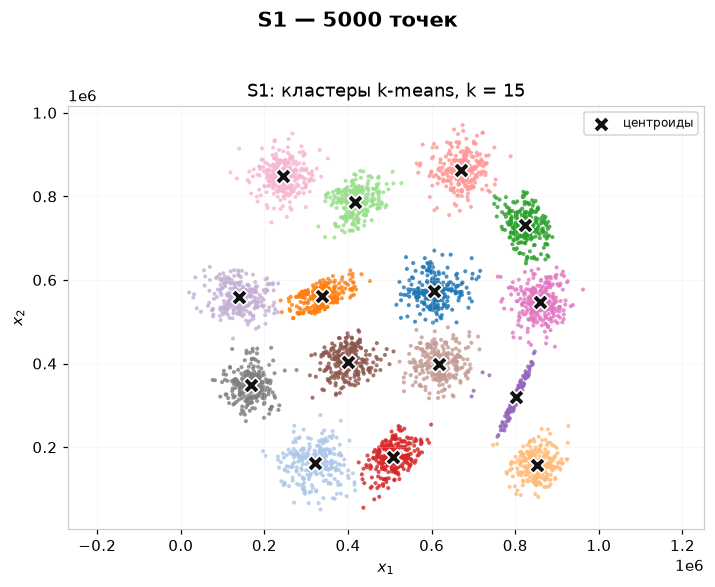

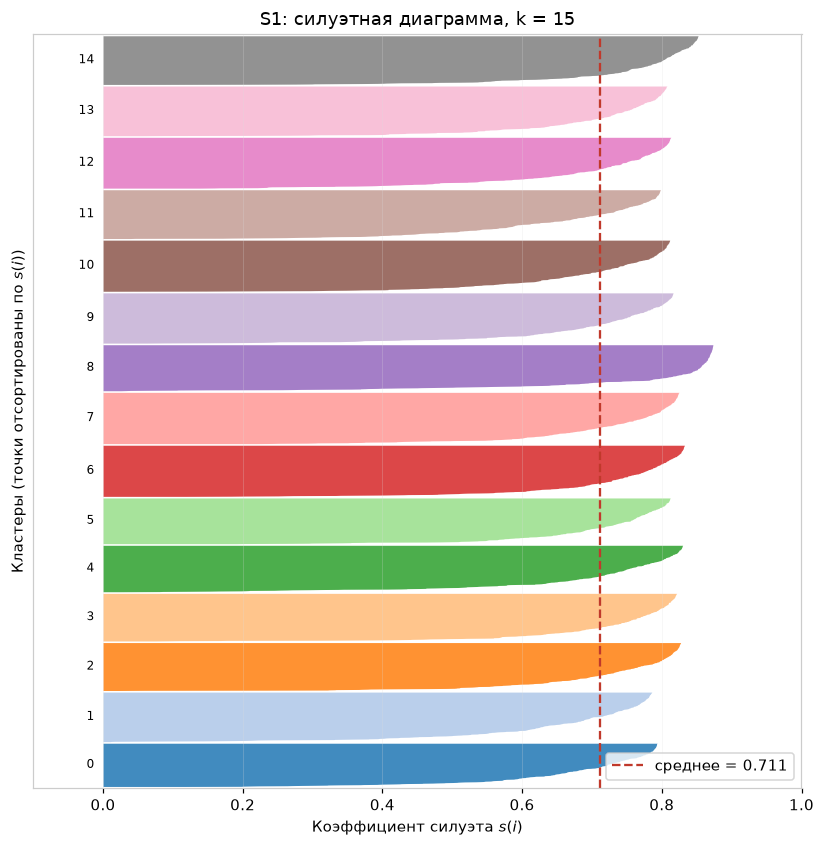

In [12]:
res_s1 = run_case('S1')

**Вывод.** Силуэт ≈ 0,71, размеры кластеров 297–352 — очень хорошая внутренняя оценка. Визуально 15 групп выделены чисто. Без истинных меток нельзя посчитать ARI/NMI, но по совокупности внутренних метрик k-means с этим набором справился.

### 5.10. Spiral — 3 кластера

`data/spiral.txt` · **312 точек** · 3 класса примерно по 100 точек.

Три перемешанные спирали — худший сценарий для k-means: кластеры невыпуклые, а точки разных классов расположены вплотную друг к другу.

**Метрики:** силуэт = **0.360**, ARI = **-0.006**, NMI = **0.001**, CH = **238.3**, DB = **0.886**, итераций = **8**; размеры кластеров: **100–109** (отношение max/min ≈ **1.1×**).

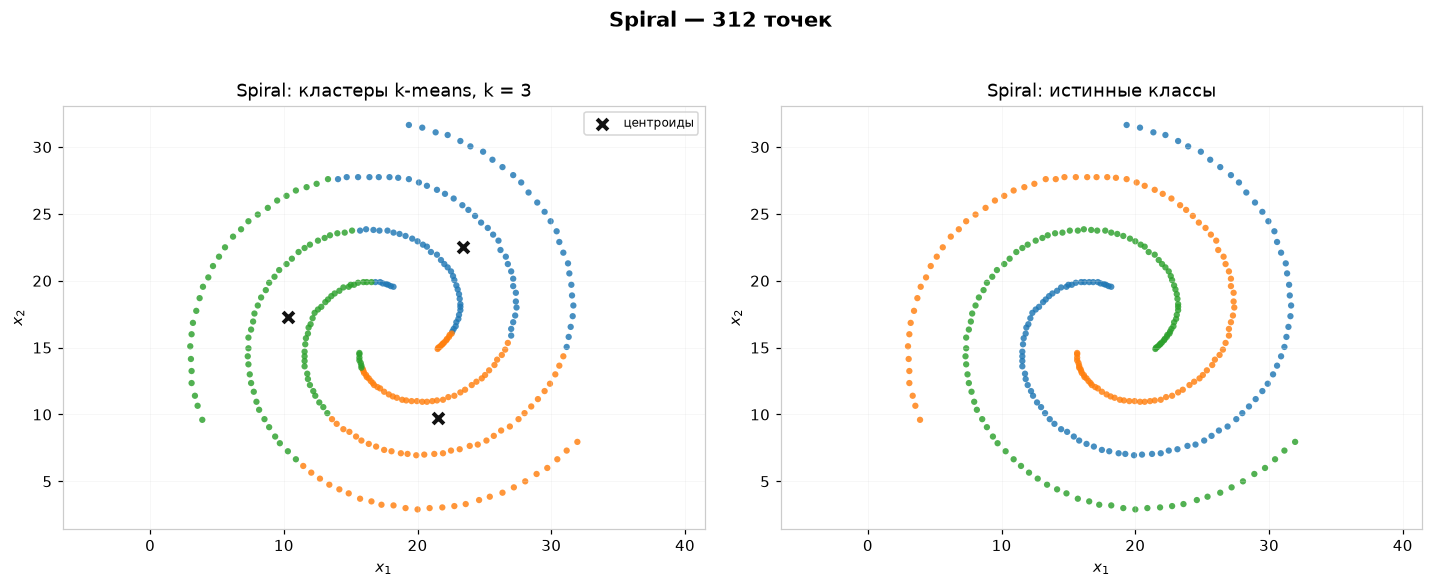

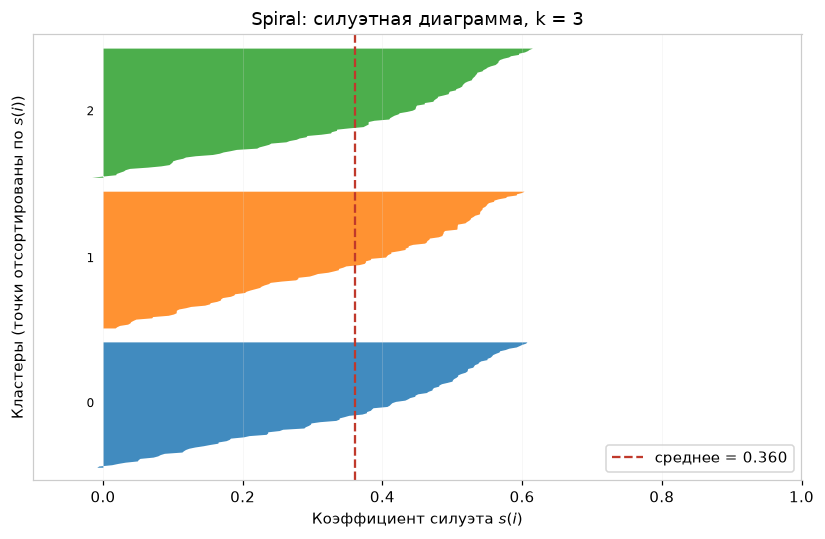

In [13]:
res_spiral = run_case('Spiral')

**Вывод.** ARI ≈ 0,00, NMI ≈ 0,00, силуэт ≈ 0,36. Каждый кластер содержит примерно по 1/3 точек каждой спирали: k-means разрезал плоскость на три сектора, а не выделил ветви спиралей. Это ключевой пример ограничения: алгоритм строит выпуклые области и не видит нелинейную структуру данных.

## 6. Сводная таблица

Собираем результаты всех запусков в одну таблицу. ARI и NMI показаны только для наборов, где в файле есть истинные метки.

In [14]:
summary_rows = []

for name, result in RESULTS.items():
    sizes = result["sizes"]
    summary_rows.append(
        {
            "Набор": name,
            "n": len(result["X"]),
            "k": result["k"],
            "Силуэт": round(result["silhouette"], 3),
            "ARI": fmt(result["ari"]),
            "NMI": fmt(result["nmi"]),
            "CH": round(result["ch"], 1),
            "DB": round(result["db"], 3),
            "Итераций": result["n_iter"],
            "Размеры": f"{sizes.min()}–{sizes.max()}",
        }
    )

summary = pd.DataFrame(summary_rows)
display(summary)

,Набор,n,k,Силуэт,ARI,NMI,CH,DB,Итераций,Размеры
0,A1,3000,20,0.595,—,—,13830.0,0.527,5,143–158
1,Aggregation,788,7,0.481,0.762,0.879,1396.6,0.731,5,47–168
2,Compound,399,6,0.432,0.538,0.719,870.6,0.845,10,39–90
3,D31,3100,31,0.576,0.954,0.968,9168.1,0.547,15,96–104
4,Flame,240,2,0.378,0.453,0.399,157.2,1.115,4,114–126
5,Jain,373,2,0.495,0.318,0.366,503.5,0.783,3,176–197
6,Pathbased,300,3,0.542,0.461,0.546,359.1,0.669,3,33–134
7,R15,600,15,0.753,0.993,0.994,4872.0,0.315,7,39–41
8,S1,5000,15,0.711,—,—,22675.3,0.367,5,297–352
9,Spiral,312,3,0.360,-0.006,0.001,238.3,0.886,8,100–109


## 7. Ответ на вопрос: справился ли k-means?

### 7.1. Итог по наборам

| Набор | Вердикт | Что произошло |
|---|---|---|
| **A1** | да (по внутренним метрикам) | 20 компактных групп, высокий силуэт; меток нет |
| **Aggregation** | в основном | большая группа разрезана, две маленькие слиты |
| **Compound** | нет | большой класс разделён, близкие классы перепутаны |
| **D31** | да | почти идеальное совпадение с классами |
| **Flame** | частично | линейная граница режет вытянутое облако |
| **Jain** | нет | большой серп разделён, часть его слита с малым классом |
| **Pathbased** | частично | кольцо разрезано на части, внутренние группы восстановлены |
| **R15** | да | почти идеальное совпадение с классами |
| **S1** | да (по внутренним метрикам) | 15 компактных групп, высокий силуэт; меток нет |
| **Spiral** | нет | спирали разрезаны на радиальные секторы |

### 7.2. Какие ограничения k-means помешали

1. **Только выпуклые кластеры и линейные границы.** K-means делит пространство на ячейки Вороного. Поэтому он не может выделить спираль, серп или кольцо: на `Spiral` ARI ≈ 0, на `Jain` — около 0,32, на `Pathbased` — около 0,46.

2. **Оптимизируется компактность, а не форма кластера.** Большие вытянутые облака разрезаются, а маленькие близкие группы сливаются. Это видно на `Aggregation` (большой класс 4 разрезан, классы 5 и 7 слиты) и `Compound` (класс 5 разделён, части классов 1 и 2 перепутаны).

3. **Неявная ориентация на сопоставимые размеры, плотность и разброс.** Функция потерь благоприятствует примерно одинаковым компактным кластерам. При сильном дисбалансе (`Flame`, `Compound`, `Aggregation`) k-means выбирает удобное с точки зрения инерции, а не истинное разбиение.

4. **Число кластеров нужно задать заранее.** K-means не определяет k сам. В `Compound` даже правильное k = 6 не гарантирует правильных границ: внутренняя структура большого класса не совпадает с числом классов. Выбор k по методу локтя или силуэту — эвристика, а не доказательство.

5. **Силуэт не равен правильности.** Silhouette использует евклидову компактность — примерно то же, что оптимизирует k-means. Поэтому на `Jain` (0,50) и `Pathbased` (0,54) он выглядит неплохо, хотя ARI низкий. Внутренняя метрика может «одобрять» неверное с точки зрения предметной области разбиение.

6. **Инициализация и выбросы.** K-means сходится к локальному минимуму и чувствителен к начальным центроидам; `n_init=50` снижает этот риск, но не устраняет его полностью. Выбросы и сильно вытянутые облака могут смещать центроиды.

### 7.3. Что могло бы помочь

- для невыпуклых кластеров — **DBSCAN/HDBSCAN**, **спектральная кластеризация**, агломеративная кластеризация с графом связности;
- для вытянутых эллиптических компонент — **Gaussian Mixture** с полной ковариационной матрицей;
- для сложных форм — **kernel k-means** или методы, работающие с расстоянием вдоль многообразия;
- подбор k по нескольким критериям (метод локтя, силуэт, gap-statistic) и проверка на отложенных данных/предметной области;
- масштабирование признаков и удаление выбросов, если они есть.

### 7.4. Общий вывод

K-means — быстрый и точный инструмент для **компактных, примерно изотропных, хорошо разделённых кластеров** (`D31`, `R15`, `A1`, `S1`). На таких данных он даёт почти идеальное разбиение.

Но k-means не является универсальным: на невыпуклых, вытянутых, кольцевых и спиральных структурах (`Spiral`, `Jain`, `Pathbased`, `Flame`) его границы не совпадают с истинными классами. Главный вывод: качество зависит не от реализации, а от **соответствия геометрии данных модели алгоритма**. Одного силуэта для вывода о качестве недостаточно — нужны внешние метки или содержательная интерпретация.

## 8. Как воспроизвести

1. Установить зависимости: `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `jupyter`.
2. Запустить ноутбук из корня проекта (рядом с папкой `data/`).
3. Выполнить все ячейки сверху вниз.

Все результаты детерминированы при `random_state=42` и `n_init=50`. Папка `data/` уже содержит все 10 наборов, использованных в работе.